In [1]:
#Instalación de librerías necesarias para el código de Bitalino

%pip install bitalino #Descargamos librería de Bitalino
%pip install scipy

#Recordar usar Python 3.10.11


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
#Importamos librerías

import bitalino

import csv

import os

import time

from IPython.display import HTML, display, Javascript

In [72]:
#Configuración del Bitalino

PUERTO = "/dev/tty.bitalino"# Puerto Bluetooth correspondiente al Bitalino

CANAL = 0# A1 = 0, A2 = 1, A3 = 2, etc...

PERIODO = 0.001# (1,0.1,0.01) Cantidad de segundos en que se demora en realizar las mediciones de forma consecutiva desde el inicio del experimento

N = 1000# Número de mediciones realizadas en bloques, cuando se capturen las {N} observaciones serán enviadas al dispotivo receptor para ser
#almacenadas en el .CSV y visualizadas en tiempo real.

#Si {N} = 1 entonces los datos se envian actualizan el CSV y visualizador en tiempo real, si es mayor a 0 entonces se espera a juntar {N}
#observaciones para enviar los datos, actualizar el CSV y el visualizador.

DURACION = 10 * 60# Cantidad de segundos en que se demora en realizarse el experimento

# Parámetros de procesamiento y calidad de señal
MAINS_NOTCH_HZ = (50.0, 100.0, 150.0, 250.0)  # Red de 50 Hz y armónicas observadas en las grabaciones
NOTCH_Q = 30.0
NOTCH_CASCADA = 2  # Notches idénticos en cascada por frecuencia (uno solo dejaba RMS de reposo de 8-28 counts)
ADC_CLIP_MIN = 0
ADC_CLIP_MAX = 1023
QUALITY_LINE_HZ = (50.0, 100.0, 150.0, 250.0)
QUALITY_LINE_HALF_BAND_HZ = 2.0
QUALITY_FLOOR_BAND_HZ = (3.0, 10.0)
QUALITY_WELCH_WINDOW_S = 2.0
HUM_CHECK_BAND_HZ = (145.0, 155.0)
HUM_RESIDUAL_BAND_HZ = 5.0  # Banda ± alrededor de cada armónica para medir ruido de red residual
SETTLING_S = 2.0  # Con la cascada de notches el transitorio dura ~2 s
REST_CHECK_S = 15.0
MAINS_AMPLITUDE_LIMIT_COUNTS = 100.0  # PROVISIONAL: calibrate after first clean recordings
RMS_ACTIVE_K = 3.0
RMS_ACTIVE_MIN_RATIO = 3.0  # Umbral Active = max(mediana + K·SD, RATIO × mediana). Con reposo limpio la SD es ~0.1-0.4 counts y K·SD solo es demasiado estricto
REST_MAX_MIN_RATIO = 4.0  # PROVISIONAL: bloque de reposo máx/mín permitido; si es mayor, no se estaba en reposo
RMS_FALLBACK_INIT_S = 5.0

# Parámetros de tendencia y fatiga
TREND_INTERVAL_S = 5.0
BASELINE_ACTIVE_S = 10.0
RMS_INCREASE_THRESHOLD = 0.20  # UNVALIDATED placeholders: calibrate with sustained holds at fixed %MVC, not from these tests
MDF_DECREASE_THRESHOLD = 0.15  # UNVALIDATED placeholders: calibrate with sustained holds at fixed %MVC, not from these tests
USE_SLOPE_TEST = True
SLOPE_WINDOW_S = 20.0
SLOPE_P_THRESHOLD = 0.05
SLOPE_MIN_POINTS = 5  # Mínimo de bloques Active dentro de la ventana
SLOPE_MIN_SPAN_FRACTION = 0.75  # Los bloques Active deben cubrir al menos esta fracción de SLOPE_WINDOW_S
FATIGUE_ALERT_THRESHOLD = 60.0  # PLACEHOLDER no validado. Con 60 el índice ya implica RMS ≥ +20% y MDF ≤ −20%: los umbrales anteriores solo actúan si bajas este valor

# Parámetros opcionales de MVC y validación offline
MVC_S = 5.0  # Duración de cada contracción máxima (los primeros SETTLING_S no cuentan)
MVC_TRIALS = 3  # Ensayos; MVC_RMS = el bloque de 1 s con mayor RMS de todos
MVC_REST_S = 30.0  # Descanso entre ensayos
MVC_COUNTDOWN_S = 3  # Cuenta regresiva antes de cada ensayo
MVC_RMS = None
SOBRESCRIBIR_ARCHIVOS = False  # Si es False, cada grabación usa el siguiente número EMG_TestNN disponible.
OFFLINE_CSV_PATH = ""
OFFLINE_SEGMENT_S = 10.0
OFFLINE_SEGMENT_LABELS = ("reposo", "contracción", "reposo", "contracción", "reposo", "contracción")
OFFLINE_BLOCK_S = 1.0

In [4]:
#Simulador EMG 
# (Alternativa al Bitalino, para probar el código sin necesidad de tener el dispositivo)

import math
import random
import time

VELOCIDAD_SIMULACION = 1.0  # 1.0 = tiempo real; 2.0 = doble de rápida, etc
MODO_EMG = "fatiga"         # "normal", "fatiga" o "contraccion"

class BITalinoSimulado:
    MODOS_VALIDOS = {"normal", "fatiga", "contraccion"}

    def __init__(self, semilla=42, velocidad=1.0, modo="normal"):
        self.rng = random.Random(semilla)
        self.velocidad = velocidad
        self.modo = modo.lower()
        self.muestra_actual = 0
        self.fs = None
        self.iniciado = False

        if self.modo not in self.MODOS_VALIDOS:
            raise ValueError(f"Modo inválido. Elige uno de: {sorted(self.MODOS_VALIDOS)}")
        if not math.isfinite(self.velocidad) or self.velocidad <= 0:
            raise ValueError("La velocidad debe ser un número mayor que cero.")

    def start(self, frecuencia_muestreo, canales):
        if frecuencia_muestreo <= 0:
            raise ValueError("La frecuencia de muestreo debe ser mayor que cero.")

        self.fs = frecuencia_muestreo
        self.muestra_actual = 0
        self.iniciado = True
        self.inicio_reloj = time.monotonic()

    def read(self, cantidad):
        if not self.iniciado:
            raise RuntimeError("La adquisición simulada no está iniciada.")
        if cantidad < 0:
            raise ValueError("La cantidad de muestras no puede ser negativa.")

        tramas = []
        for _ in range(cantidad):
            t = self.muestra_actual / self.fs
            # Los primeros REST_CHECK_S segundos son reposo (ruido y amplitud mínima): ahí graba la
            # comprobación de reposo, y la adquisición empieza igual. Después sigue el modo elegido.
            t_activo = t - REST_CHECK_S
            progreso = (
                min(max(t_activo, 0.0) / (DURACION - REST_CHECK_S), 1.0)
                if DURACION > REST_CHECK_S else 0.0
            )

            if t_activo < 0:
                amplitud = 4
                pesos = [0.5, 1.0, 1.2, 0.8]
            elif self.modo == "fatiga":
                # Amplitud creciente y menor peso de componentes de alta frecuencia.
                amplitud = 25 + 55 * progreso
                pesos = [
                    0.5 + 0.4 * progreso,
                    1.0,
                    1.2 - 0.8 * progreso,
                    0.8 - 0.65 * progreso,
                ]
            elif self.modo == "contraccion":
                # Simula ciclos de 3 s de contracción y 3 s de reposo.
                en_contraccion = (t_activo % 6) < 3
                amplitud = 75 if en_contraccion else 4
                pesos = [0.5, 1.0, 1.2, 0.8]
            else:  # normal
                amplitud = 40
                pesos = [0.5, 1.0, 1.2, 0.8]

            frecuencias = [0.06, 0.12, 0.22, 0.38]
            senal = sum(
                peso * math.sin(2 * math.pi * fraccion * self.fs * t)
                for fraccion, peso in zip(frecuencias, pesos)
            )
            emg_adc = int(
                max(0, min(1023, 512 + amplitud * senal + self.rng.gauss(0, 8)))
            )

            tramas.append([0, 0, 0, 0, 0, emg_adc])
            self.muestra_actual += 1

        tiempo_objetivo = self.muestra_actual / (self.fs * self.velocidad)
        espera = tiempo_objetivo - (time.monotonic() - self.inicio_reloj)
        if espera > 0:
            time.sleep(espera)

        return tramas

    def stop(self):
        self.iniciado = False


device = BITalinoSimulado(
    velocidad=VELOCIDAD_SIMULACION,
    modo=MODO_EMG,
)
print(f"Simulación: modo {MODO_EMG}, velocidad {VELOCIDAD_SIMULACION}x.")

Simulación: modo fatiga, velocidad 1.0x.


In [5]:
#Inicialización de HTML

# visualizador.html ya no es necesario para el panel (se usa matplotlib); si falta, se continúa sin él.
try:
    with open("visualizador.html", "r", encoding="utf-8") as archivo:
        Visualizador_HTML = archivo.read()
except FileNotFoundError:
    Visualizador_HTML = None
    print("Aviso: visualizador.html no encontrado en", os.getcwd(), "- se continúa sin él.")


In [89]:
#Inciar Conexión con el Bitalino

device = bitalino.BITalino(PUERTO)#abre la conexión con el BITalino usando el puerto indicado {PUERTO}

In [36]:
#Procesador sEMG

import numpy as np #Importamos librería para cálculos numéricos
from scipy.signal import butter, iirnotch, sosfilt, sosfilt_zi, tf2sos, welch #Importamos librería para procesamiento de señales

# Clase para procesar señales EMG
class ProcesadorEMG:
    # Inicializa el procesador con la frecuencia de muestreo especificada.
    def __init__(self, frecuencia_muestreo):
        self.fs = frecuencia_muestreo
        if self.fs <= 800:
            raise ValueError(
                "The 25–400 Hz EMG band requires a sampling rate above 800 Hz."
            )

        # Cada notch se aplica primero; las secciones SOS conservan su estado entre bloques.
        secciones_notch = [
            tf2sos(*iirnotch(frecuencia, Q=NOTCH_Q, fs=self.fs))
            for frecuencia in MAINS_NOTCH_HZ
            for _ in range(NOTCH_CASCADA)
        ]
        sos_bandpass = butter(
            4, [25, 400], btype="bandpass", fs=self.fs, output="sos"
        )
        self.sos = np.vstack((*secciones_notch, sos_bandpass))
        self.estado_filtro = None
        self.ultima_filtrada = np.array([], dtype=float)

    def procesar_bloque(self, muestras):
        valores = np.asarray([float(valor) for _, valor in muestras], dtype=float)
        if valores.size < 32:
            raise ValueError(
                "The EMG block is too short for reliable spectral analysis."
            )
        if self.estado_filtro is None:
            self.estado_filtro = sosfilt_zi(self.sos) * valores[0]
        self.ultima_filtrada, self.estado_filtro = sosfilt(
            self.sos, valores, zi=self.estado_filtro
        )

        rms = float(np.sqrt(np.mean(self.ultima_filtrada ** 2)))
        nperseg = min(valores.size, max(32, round(self.fs * 0.5)))
        frecuencias, potencia = welch(
            self.ultima_filtrada,
            fs=self.fs,
            window="hann",
            nperseg=nperseg,
            noverlap=nperseg // 2,
            detrend="constant",
            scaling="density",
        )
        banda = (frecuencias >= 25) & (frecuencias <= 400)
        frecuencias_banda = frecuencias[banda]
        potencia_banda = potencia[banda]
        potencia_total = float(np.sum(potencia_banda))
        if potencia_total <= 0 or frecuencias_banda.size == 0:
            return rms, float("nan")

        acumulada = np.cumsum(potencia_banda)
        indice = min(
            int(np.searchsorted(acumulada, potencia_total / 2)),
            frecuencias_banda.size - 1,
        )
        if indice == 0:
            mdf = float(frecuencias_banda[0])
        else:
            potencia_previa = acumulada[indice - 1]
            potencia_actual = potencia_banda[indice]
            fraccion = (
                (potencia_total / 2 - potencia_previa) / potencia_actual
                if potencia_actual > 0 else 0.0
            )
            mdf = float(
                frecuencias_banda[indice - 1]
                + fraccion
                * (frecuencias_banda[indice] - frecuencias_banda[indice - 1])
            )
        return rms, mdf


def evaluar_calidad(muestras_crudas, frecuencia_muestreo):
    """Resume clipping y componentes de línea sobre muestras ADC crudas."""
    valores = np.asarray(muestras_crudas, dtype=float)
    if valores.size < 32:
        raise ValueError("Se requieren al menos 32 muestras para evaluar calidad.")
    clipped = (valores <= ADC_CLIP_MIN) | (valores >= ADC_CLIP_MAX)
    nperseg = min(
        valores.size, max(32, round(frecuencia_muestreo * QUALITY_WELCH_WINDOW_S))
    )
    frecuencias, potencia = welch(
        valores, fs=frecuencia_muestreo, nperseg=nperseg,
        noverlap=nperseg // 2, detrend="constant", scaling="density"
    )
    paso_hz = frecuencia_muestreo / nperseg
    lineas = {}
    razones = {}
    frecuencias_lineas = sorted(set(QUALITY_LINE_HZ).union(MAINS_NOTCH_HZ))
    for hz in frecuencias_lineas:
        cerca = np.abs(frecuencias - hz) <= QUALITY_LINE_HALF_BAND_HZ
        piso = (np.abs(frecuencias - hz) >= QUALITY_FLOOR_BAND_HZ[0]) & (
            np.abs(frecuencias - hz) <= QUALITY_FLOOR_BAND_HZ[1]
        )
        lineas[hz] = float(np.sqrt(np.sum(potencia[cerca]) * paso_hz))
        piso_local = float(np.median(potencia[piso])) if np.any(piso) else 0.0
        pico_local = float(np.max(potencia[cerca])) if np.any(cerca) else 0.0
        razones[hz] = (
            pico_local / piso_local if piso_local > 0
            else (float("inf") if pico_local > 0 else float("nan"))
        )
    return {
        "clipped_count": int(np.count_nonzero(clipped)),
        "clipped_percent": float(100 * np.mean(clipped)),
        "line_rms": lineas,
        "peak_ratio": razones,
    }


def texto_calidad(calidad):
    marcas = []
    if calidad["clipped_count"]:
        marcas.append(f"CLIPPED:{calidad['clipped_count']}")
    amplitud_maxima = max(
        calidad["line_rms"].get(hz, 0.0) for hz in MAINS_NOTCH_HZ
    )
    if amplitud_maxima > MAINS_AMPLITUDE_LIMIT_COUNTS:
        marcas.append("MAINS_WARN")
    if not rest_check_passed:
        marcas.append("REST_CHECK_WARN")
    return ";".join(marcas) if marcas else "OK"


def dispositivo_es_simulado():
    """True si `device` es el simulador (un PASS con datos simulados no valida el hardware)."""
    return type(device).__name__ == "BITalinoSimulado"


In [90]:
#Adquisición sEMG

#Calcula tendencias de RMS/MDF y un índice de fatiga de 0 a 100%.
#El índice no está validado; no existe una referencia de fuerza en este protocolo.

import csv
import math
import statistics
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from collections import deque
from scipy.stats import linregress

FS = 1 / PERIODO
if not 0 <= FATIGUE_ALERT_THRESHOLD <= 100:
    raise ValueError("FATIGUE_ALERT_THRESHOLD debe estar entre 0 y 100.")
if TREND_INTERVAL_S <= 0 or BASELINE_ACTIVE_S <= 0:
    raise ValueError("TREND_INTERVAL_S y BASELINE_ACTIVE_S deben ser mayores que cero.")
if REST_CHECK_S <= 0 or SETTLING_S < 0 or SLOPE_WINDOW_S <= 0:
    raise ValueError("REST_CHECK_S y SLOPE_WINDOW_S deben ser positivos; SETTLING_S no puede ser negativo.")
if not 0 < SLOPE_P_THRESHOLD <= 1:
    raise ValueError("SLOPE_P_THRESHOLD debe estar entre 0 y 1.")
TREND_WINDOW_S = 30
RAW_WINDOW_S = 5
BLOCK_WINDOW_S = 30
baseline_rms = []
baseline_mdf = []
baseline_active_elapsed = 0.0
rms_baseline_level = None
mdf_baseline_level = None
rest_rms_median = None
rest_rms_robust_sd = None
rest_check_passed = False
alerta_fatiga_activada = False
fallback_rms_history = []
slope_history = []
ultimo_active = False
ultimo_quality_flag = "PENDIENTE"
ultimo_fatigue_reason = "La comprobación de reposo no se ha ejecutado."
ultimo_mensaje_supresion = None

archivo_features_csv = "EMG_Test01.csv"
archivo_crudo_csv = "EMG_Test01_crudo.csv"
archivo_bloques_csv = "EMG_Test01_bloques.csv"
tiempos_tendencia, rms_tendencia, mdf_tendencia, fatiga_tendencia = [], [], [], []
bin_tiempos, bin_rms, bin_mdf, bin_fatiga = [], [], [], []
bin_active, bin_active_rms, bin_active_mdf = [], [], []
bin_duraciones, bin_quality, bin_rms_mvc = [], [], []
raw_tiempos = deque(maxlen=max(1, int(RAW_WINDOW_S * FS)))
raw_valores = deque(maxlen=max(1, int(RAW_WINDOW_S * FS)))
bloques_tiempos, bloques_rms, bloques_mdf = [], [], []


def robust_sd(valores):
    if not valores:
        return float("nan")
    mediana = statistics.median(valores)
    return 1.4826 * statistics.median(
        [abs(valor - mediana) for valor in valores]
    )


def umbral_actividad(mediana, sd):
    """Umbral Active = max(mediana + K·SD, RATIO × mediana).
    Con reposo limpio la SD robusta es ~0.1-0.4 counts y mediana + 3·SD daba
    especificidad de 0.60-0.90; el piso relativo la deja en 0.80-0.90 (los
    falsos positivos que quedan son el primer segundo tras soltar).
    """
    return max(mediana + RMS_ACTIVE_K * sd, RMS_ACTIVE_MIN_RATIO * mediana)


def detectar_actividad(rms, asentamiento):
    global fallback_rms_history
    if asentamiento:
        return False, "periodo de asentamiento"
    if rest_rms_median is not None and rest_rms_robust_sd is not None:
        umbral = umbral_actividad(rest_rms_median, rest_rms_robust_sd)
        return rms > umbral, f"umbral de reposo {umbral:.3f}"

    muestras_iniciales = max(1, math.ceil(RMS_FALLBACK_INIT_S))
    if len(fallback_rms_history) < muestras_iniciales:
        fallback_rms_history.append(rms)
        return False, (
            f"estimación móvil sin calibración; reuniendo "
            f"{len(fallback_rms_history)}/{muestras_iniciales} bloques"
        )
    umbral = umbral_actividad(
        statistics.median(fallback_rms_history), robust_sd(fallback_rms_history)
    )
    activo = rms > umbral
    if not activo:
        fallback_rms_history.append(rms)
        fallback_rms_history = fallback_rms_history[-60:]
    return activo, f"estimación móvil sin calibración; umbral {umbral:.3f}"


def calcular_fatiga(rms, mdf, activo, asentamiento, duracion_bloque):
    """Índice = 100 × promedio de [clip(RMS/RMS_base − 1, 0, 1),
    clip(1 − MDF/MDF_base, 0, 1)]. La base son los primeros
    BASELINE_ACTIVE_S segundos activos no asentados. NaN si no hay
    comprobación de reposo PASS, el bloque no está activo o falta la base.
    Los umbrales y este índice son placeholders no validados; no implican
    diagnóstico clínico ni reemplazan una referencia de fuerza.
    """
    global rms_baseline_level, mdf_baseline_level, baseline_active_elapsed
    if asentamiento or not activo or not rest_check_passed:
        return float("nan")
    if not (math.isfinite(rms) and math.isfinite(mdf)) or rms <= 0 or mdf <= 0:
        return float("nan")
    if rms_baseline_level is None or mdf_baseline_level is None:
        tiempo_restante = BASELINE_ACTIVE_S - baseline_active_elapsed
        if tiempo_restante > 0:
            baseline_rms.append(rms)
            baseline_mdf.append(mdf)
            baseline_active_elapsed += min(duracion_bloque, tiempo_restante)
        if baseline_active_elapsed < BASELINE_ACTIVE_S:
            return float("nan")
        rms_baseline_level = statistics.median(baseline_rms)
        mdf_baseline_level = statistics.median(baseline_mdf)
        return 0.0
    aumento_rms = min(1.0, max(0.0, rms / rms_baseline_level - 1.0))
    descenso_mdf = min(1.0, max(0.0, 1.0 - mdf / mdf_baseline_level))
    return 100.0 * (aumento_rms + descenso_mdf) / 2.0


def prueba_pendientes(tiempo_actual):
    """Regresión de RMS y MDF sobre los bloques Active de los últimos SLOPE_WINDOW_S.
    Antes exigía span >= SLOPE_WINDOW_S exacto con floats: fallaba ~24% de las
    evaluaciones por redondeo, y miraba un bloque del intervalo siguiente.
    """
    if not USE_SLOPE_TEST:
        return True
    tolerancia = 1e-6
    puntos = [
        punto for punto in slope_history
        if tiempo_actual - SLOPE_WINDOW_S - tolerancia <= punto[0] <= tiempo_actual + tolerancia
    ]
    if len(puntos) < SLOPE_MIN_POINTS:
        return False
    if puntos[-1][0] - puntos[0][0] < SLOPE_MIN_SPAN_FRACTION * SLOPE_WINDOW_S:
        return False
    tiempos = [punto[0] for punto in puntos]
    ajuste_rms = linregress(tiempos, [punto[1] for punto in puntos])
    ajuste_mdf = linregress(tiempos, [punto[2] for punto in puntos])
    return (
        ajuste_rms.slope > 0 and ajuste_rms.pvalue < SLOPE_P_THRESHOLD
        and ajuste_mdf.slope < 0 and ajuste_mdf.pvalue < SLOPE_P_THRESHOLD
    )


def cerrar_intervalo(escritor_features, archivo_features, parcial=False):
    global alerta_fatiga_activada, ultimo_fatigue_reason, ultimo_mensaje_supresion
    if not bin_tiempos:
        return
    duracion_intervalo = sum(bin_duraciones)
    parcial = parcial or duracion_intervalo < TREND_INTERVAL_S - 1e-6
    rms_resumen = statistics.mean(bin_rms) if bin_rms else float("nan")
    mdf_resumen = (
        statistics.median(bin_mdf) if bin_mdf else float("nan")
    )
    fatiga_resumen = (
        statistics.median(bin_fatiga) if bin_fatiga else float("nan")
    )
    segundos_activos = sum(
        duracion for activo, duracion in zip(bin_active, bin_duraciones)
        if activo
    )
    tiempo_tendencia = intervalo_actual * TREND_INTERVAL_S + min(
        TREND_INTERVAL_S, duracion_intervalo
    ) / 2
    marcas = sorted({marca for marca in bin_quality if marca != "OK"})
    calidad_resumen = ";".join(marcas) if marcas else "OK"

    if not rest_check_passed:
        ultimo_fatigue_reason = "índice suprimido: la comprobación de reposo no fue PASS"
    elif not bin_active_rms:
        ultimo_fatigue_reason = "índice suprimido: no hubo bloques Active"
    elif rms_baseline_level is None:
        ultimo_fatigue_reason = "índice suprimido: línea base Active aún incompleta"
    else:
        ultimo_fatigue_reason = "índice disponible solo para bloques Active"

    if (
        not alerta_fatiga_activada
        and math.isfinite(fatiga_resumen)
        and fatiga_resumen >= FATIGUE_ALERT_THRESHOLD
        and bin_active_rms and bin_active_mdf
        and rms_baseline_level is not None and mdf_baseline_level is not None
    ):
        rms_activo = statistics.median(bin_active_rms)
        mdf_activo = statistics.median(bin_active_mdf)
        umbrales_cumplidos = (
            rms_activo >= rms_baseline_level * (1 + RMS_INCREASE_THRESHOLD)
            and mdf_activo <= mdf_baseline_level * (1 - MDF_DECREASE_THRESHOLD)
        )
        pendientes_ok = prueba_pendientes(bin_tiempos[-1])
        if umbrales_cumplidos and pendientes_ok:
            alerta_fatiga_activada = True
            display(HTML(
                "<div style='padding:12px;border:2px solid #b91c1c;"
                "background:#fee2e2;color:#7f1d1d;font-weight:bold;'>"
                f"ALERTA de tendencia compatible con fatiga: índice "
                f"{fatiga_resumen:.1f}%. Resultado no validado.</div>"
            ))

    tiempos_tendencia.append(tiempo_tendencia)
    rms_tendencia.append(rms_resumen)
    mdf_tendencia.append(mdf_resumen)
    fatiga_tendencia.append(fatiga_resumen)
    actualizar_grafico(
        tiempos_tendencia, rms_tendencia, mdf_tendencia,
        fatiga_tendencia, tiempo_tendencia
    )
    actualizar_panel_adquisicion()
    fila = [
        tiempo_tendencia, rms_resumen, mdf_resumen, fatiga_resumen,
        segundos_activos, parcial,
    ]
    if MVC_RMS is not None:
        fila.append(100 * rms_resumen / MVC_RMS if math.isfinite(rms_resumen) else float("nan"))
    fila.append(calidad_resumen)
    escritor_features.writerow(fila)
    archivo_features.flush()
    if not math.isfinite(fatiga_resumen):
        if ultimo_fatigue_reason != ultimo_mensaje_supresion:  # solo cuando cambia el motivo
            print(f"Fatigue index (%) suprimido: {ultimo_fatigue_reason}.")
            ultimo_mensaje_supresion = ultimo_fatigue_reason
    if parcial:
        print(f"Intervalo final parcial ({duracion_intervalo:.2f} s); marcado como parcial.")
    bin_tiempos.clear()
    bin_rms.clear()
    bin_mdf.clear()
    bin_fatiga.clear()
    bin_active.clear()
    bin_active_rms.clear()
    bin_active_mdf.clear()
    bin_duraciones.clear()
    bin_quality.clear()
    bin_rms_mvc.clear()


n_medicion = 0
adquisicion_iniciada = False
intervalo_actual = None
procesador_emg = ProcesadorEMG(FS)
muestras_recientes = []
ultima_trama = None
ultimo_valor_emg = float("nan")
ultimo_rms = float("nan")
ultimo_mdf = float("nan")
n_mediciones_totales = int(DURACION / PERIODO)
clipping_count_recording = 0

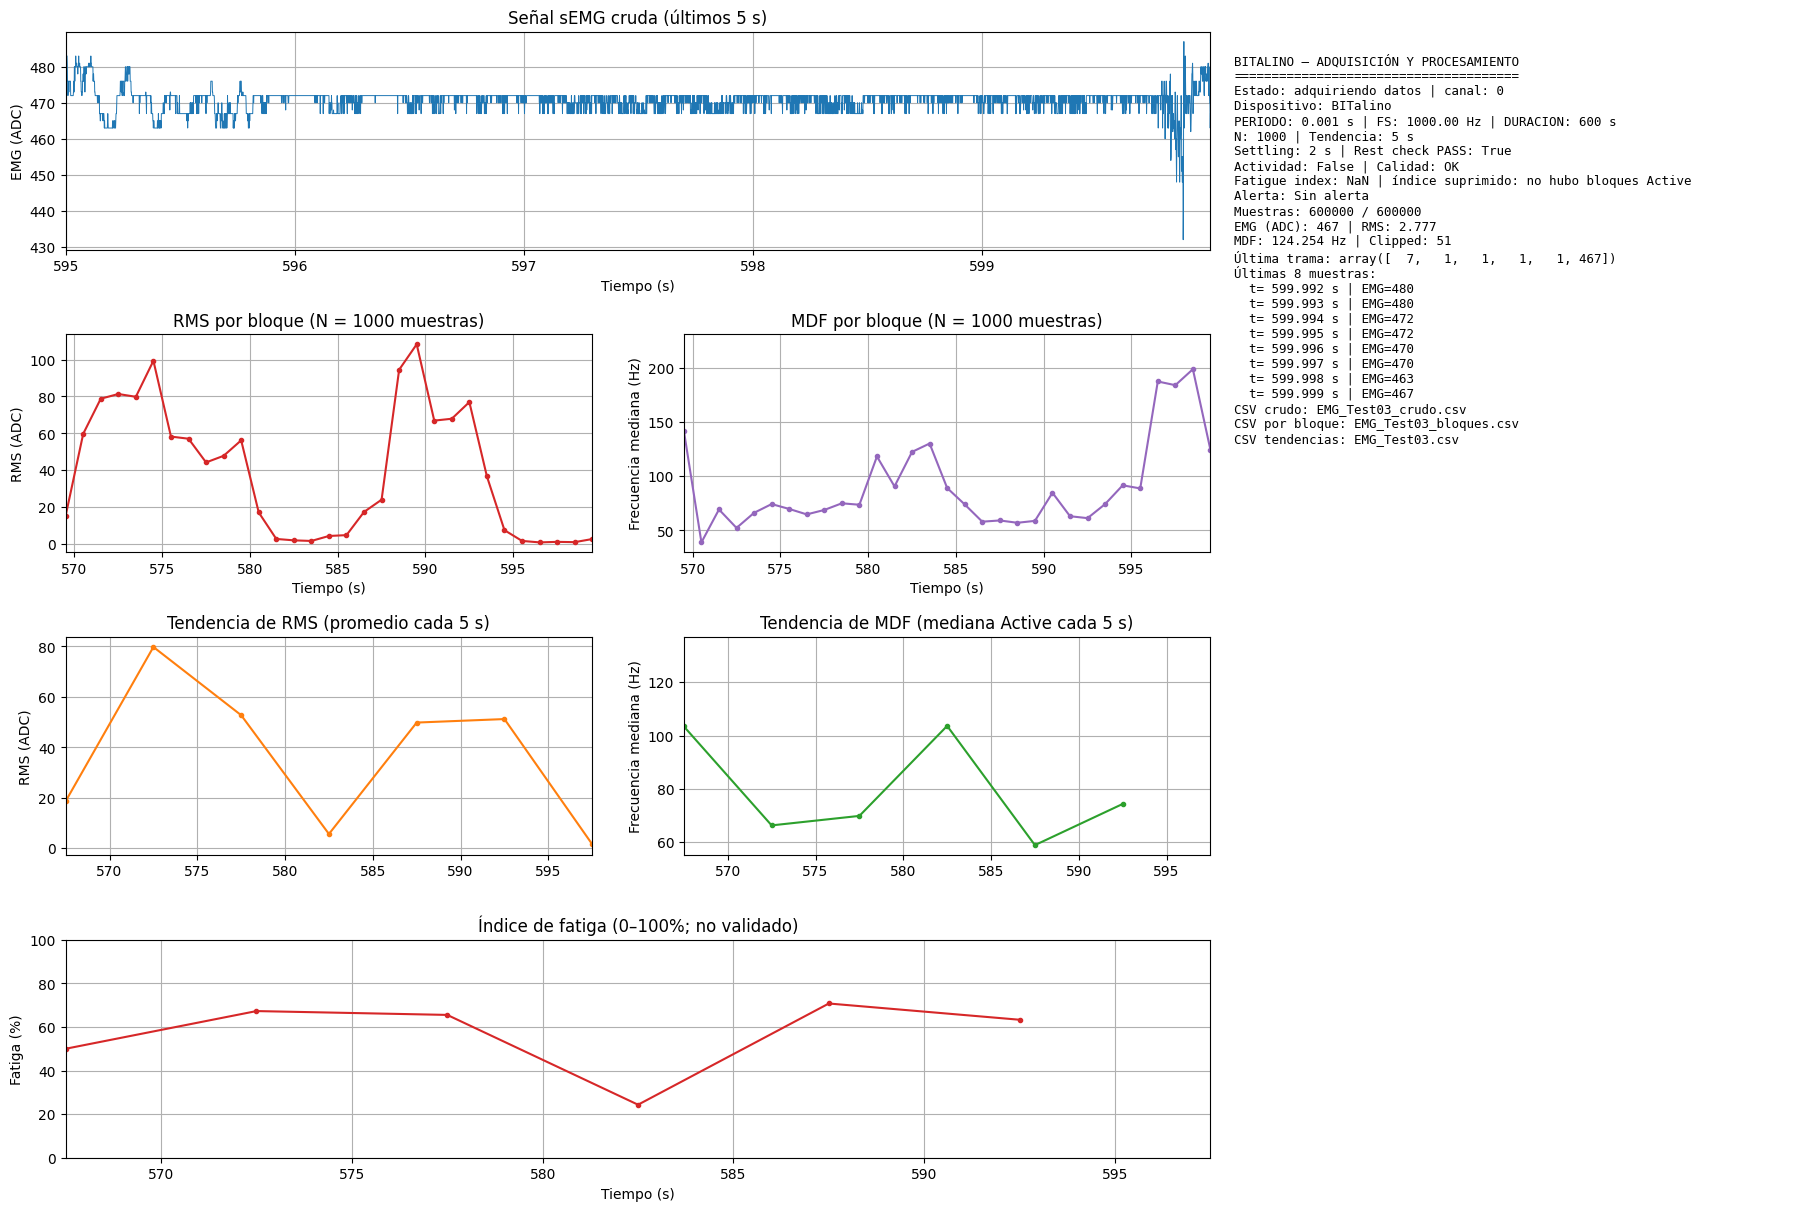

In [85]:
#Visualizador HTML

# Panel de adquisición con señal cruda, valores por bloque, tendencias e índice de fatiga.
fig = plt.figure(figsize=(18, 12), constrained_layout=True)
rejilla = fig.add_gridspec(4, 3, width_ratios=[1, 1, 1.1])
ax_raw = fig.add_subplot(rejilla[0, 0:2])
ax_rms_bloque = fig.add_subplot(rejilla[1, 0])
ax_mdf_bloque = fig.add_subplot(rejilla[1, 1])
ax_rms = fig.add_subplot(rejilla[2, 0])
ax_mdf = fig.add_subplot(rejilla[2, 1], sharex=ax_rms)
ax_fatiga = fig.add_subplot(rejilla[3, 0:2], sharex=ax_rms)
ax_info = fig.add_subplot(rejilla[:, 2])
ax_info.axis("off")

linea_crudo, = ax_raw.plot([], [], color="tab:blue", linewidth=0.7)
ax_raw.set_title(f"Señal sEMG cruda (últimos {RAW_WINDOW_S} s)")
ax_raw.set_xlabel("Tiempo (s)")
ax_raw.set_ylabel("EMG (ADC)")
ax_raw.set_xlim(0, RAW_WINDOW_S)
ax_raw.grid(True)
linea_rms_bloque, = ax_rms_bloque.plot([], [], color="tab:red", marker="o", markersize=3)
ax_rms_bloque.set_title(f"RMS por bloque (N = {N} muestras)")
ax_rms_bloque.set_xlabel("Tiempo (s)")
ax_rms_bloque.set_ylabel("RMS (ADC)")
ax_rms_bloque.set_xlim(0, BLOCK_WINDOW_S)
ax_rms_bloque.grid(True)
linea_mdf_bloque, = ax_mdf_bloque.plot([], [], color="tab:purple", marker="o", markersize=3)
ax_mdf_bloque.set_title(f"MDF por bloque (N = {N} muestras)")
ax_mdf_bloque.set_xlabel("Tiempo (s)")
ax_mdf_bloque.set_ylabel("Frecuencia mediana (Hz)")
ax_mdf_bloque.set_xlim(0, BLOCK_WINDOW_S)
ax_mdf_bloque.grid(True)
linea_rms, = ax_rms.plot([], [], color="tab:orange", marker=".")
ax_rms.set_title(f"Tendencia de RMS (promedio cada {TREND_INTERVAL_S:g} s)")
ax_rms.set_ylabel("RMS (ADC)")
ax_rms.set_xlim(0, TREND_WINDOW_S)
ax_rms.grid(True)
linea_mdf, = ax_mdf.plot([], [], color="tab:green", marker=".")
ax_mdf.set_title(f"Tendencia de MDF (mediana Active cada {TREND_INTERVAL_S:g} s)")
ax_mdf.set_ylabel("Frecuencia mediana (Hz)")
ax_mdf.grid(True)
linea_fatiga, = ax_fatiga.plot([], [], color="tab:red", marker=".")
ax_fatiga.set_title("Índice de fatiga (0–100%; no validado)")
ax_fatiga.set_xlabel("Tiempo (s)")
ax_fatiga.set_ylabel("Fatiga (%)")
ax_fatiga.set_ylim(0, 100)
ax_fatiga.grid(True)
texto_info = ax_info.text(
    0.02, 0.98, "Esperando datos del BITalino...",
    va="top", family="monospace", fontsize=9
)
grafico = display(fig, display_id=True)
plt.close(fig)


def actualizar_graficos_bloque():
    if raw_tiempos:
        linea_crudo.set_data(list(raw_tiempos), list(raw_valores))
        ax_raw.relim()
        ax_raw.autoscale_view(scalex=False, scaley=True)
        derecha = max(RAW_WINDOW_S, raw_tiempos[-1])
        ax_raw.set_xlim(derecha - RAW_WINDOW_S, derecha)
    if bloques_tiempos:
        linea_rms_bloque.set_data(bloques_tiempos, bloques_rms)
        linea_mdf_bloque.set_data(bloques_tiempos, bloques_mdf)
        derecha = max(BLOCK_WINDOW_S, bloques_tiempos[-1])
        for eje in (ax_rms_bloque, ax_mdf_bloque):
            eje.relim()
            eje.autoscale_view(scalex=False, scaley=True)
            eje.set_xlim(derecha - BLOCK_WINDOW_S, derecha)


def actualizar_panel_adquisicion():
    texto_muestras = "\n".join(
        f"  t={tiempo:8.3f} s | EMG={valor}"
        for tiempo, valor in muestras_recientes
    ) or "  Todavía no hay muestras."
    texto_trama = repr(ultima_trama)
    if len(texto_trama) > 160:
        texto_trama = texto_trama[:157] + "..."
    indice_fatiga = fatiga_tendencia[-1] if fatiga_tendencia else float("nan")
    texto_fatiga = f"{indice_fatiga:.1f}%" if math.isfinite(indice_fatiga) else "NaN"
    estado_alerta = "ALERTA" if alerta_fatiga_activada else "Sin alerta"
    texto_info.set_text(
        "BITALINO — ADQUISICIÓN Y PROCESAMIENTO\n"
        "======================================\n"
        f"Estado: adquiriendo datos | canal: {CANAL}\n"
        f"Dispositivo: {'SIMULADO' if dispositivo_es_simulado() else 'BITalino'}\n"
        f"PERIODO: {PERIODO} s | FS: {FS:.2f} Hz | DURACION: {DURACION} s\n"
        f"N: {N} | Tendencia: {TREND_INTERVAL_S:g} s\n"
        f"Settling: {SETTLING_S:g} s | Rest check PASS: {rest_check_passed}\n"
        f"Actividad: {ultimo_active} | Calidad: {ultimo_quality_flag}\n"
        f"Fatigue index: {texto_fatiga} | {ultimo_fatigue_reason}\n"
        f"Alerta: {estado_alerta}\n"
        f"Muestras: {n_medicion} / {n_mediciones_totales}\n"
        f"EMG (ADC): {ultimo_valor_emg} | RMS: {ultimo_rms:.3f}\n"
        f"MDF: {ultimo_mdf:.3f} Hz | Clipped: {clipping_count_recording}\n"
        f"Última trama: {texto_trama}\n"
        f"Últimas {len(muestras_recientes)} muestras:\n{texto_muestras}\n"
        f"CSV crudo: {archivo_crudo_csv}\n"
        f"CSV por bloque: {archivo_bloques_csv}\n"
        f"CSV tendencias: {archivo_features_csv}"
    )
    grafico.update(fig)  # refresca en cada bloque (en 3.9 solo se refrescaba cada TREND_INTERVAL_S)


def actualizar_grafico(tiempos, rms, mdf, fatiga, tiempo_actual):
    linea_rms.set_data(tiempos, rms)
    linea_mdf.set_data(tiempos, mdf)
    linea_fatiga.set_data(tiempos, fatiga)
    for eje in (ax_rms, ax_mdf):
        eje.relim()
        eje.autoscale_view(scalex=False, scaley=True)
    ax_fatiga.relim()
    ax_fatiga.set_ylim(0, 100)
    extremo_derecho = max(TREND_WINDOW_S, tiempo_actual)
    extremo_izquierdo = extremo_derecho - TREND_WINDOW_S
    for eje in (ax_rms, ax_mdf, ax_fatiga):
        eje.set_xlim(extremo_izquierdo, extremo_derecho)
    grafico.update(fig)

In [91]:
#Comprobación de reposo antes de la sesión

def comprobar_reposo_previo():
    global rest_rms_median, rest_rms_robust_sd, rest_check_passed
    rest_check_passed = False
    rest_rms_median = None
    rest_rms_robust_sd = None
    cantidad_total = round(REST_CHECK_S * FS)
    datos_crudos = []
    simulado = dispositivo_es_simulado()
    print(f"Dispositivo: {'SIMULADO' if simulado else 'BITalino real'}")
    print(f"Mantén el músculo en reposo durante {REST_CHECK_S:g} s...")
    device.start(FS, [CANAL])
    try:
        restantes = cantidad_total
        while restantes:
            cantidad = min(N, restantes)
            tramas = device.read(cantidad)
            datos_crudos.extend(int(trama[5]) for trama in tramas)
            restantes -= len(tramas)
    finally:
        device.stop()

    procesador_reposo = ProcesadorEMG(FS)
    rms_reposo, mdf_reposo, filtrada_reposo = [], [], []
    muestras_por_bloque = max(32, round(FS))
    for inicio in range(0, len(datos_crudos), muestras_por_bloque):
        bloque = datos_crudos[inicio:inicio + muestras_por_bloque]
        if len(bloque) < 32:
            continue
        muestras = [(i / FS, valor) for i, valor in enumerate(bloque)]
        rms, mdf = procesador_reposo.procesar_bloque(muestras)
        if inicio / FS >= SETTLING_S:
            rms_reposo.append(rms)
            mdf_reposo.append(mdf)
            filtrada_reposo.extend(procesador_reposo.ultima_filtrada.tolist())
    calidad = evaluar_calidad(datos_crudos, FS)
    rest_rms_median = statistics.median(rms_reposo) if rms_reposo else None
    rest_rms_robust_sd = robust_sd(rms_reposo) if rms_reposo else None
    lineas_dentro_limite = all(
        calidad["line_rms"][hz] <= MAINS_AMPLITUDE_LIMIT_COUNTS
        for hz in MAINS_NOTCH_HZ
    )
    # ¿Era realmente reposo? Los bloques de reposo no deben variar mucho entre sí.
    if rms_reposo and min(rms_reposo) > 0:
        razon_max_min = max(rms_reposo) / min(rms_reposo)
    else:
        razon_max_min = float("inf")
    reposo_estable = bool(rms_reposo) and razon_max_min <= REST_MAX_MIN_RATIO
    rest_check_passed = (
        calidad["clipped_count"] == 0
        and lineas_dentro_limite
        and rest_rms_median is not None
        and reposo_estable
    )

    # Ruido de red residual tras el filtrado (informativo; no condiciona el PASS).
    fraccion_red = float("nan")
    if len(filtrada_reposo) >= 32:
        nperseg = min(len(filtrada_reposo), round(FS))
        frecuencias, potencia = welch(
            np.asarray(filtrada_reposo), fs=FS, nperseg=nperseg,
            noverlap=nperseg // 2, detrend="constant", scaling="density",
        )
        en_banda = (frecuencias >= 25) & (frecuencias <= 400)
        cerca_red = np.zeros_like(en_banda)
        for hz in MAINS_NOTCH_HZ:
            cerca_red |= np.abs(frecuencias - hz) <= HUM_RESIDUAL_BAND_HZ
        total = float(np.sum(potencia[en_banda]))
        if total > 0:
            fraccion_red = float(np.sum(potencia[en_banda & cerca_red]) / total)

    print(f"Reposo previo: {REST_CHECK_S:g} s")
    print(
        f"Clipped: {calidad['clipped_count']} ({calidad['clipped_percent']:.4f}%)"
    )
    for hz in MAINS_NOTCH_HZ:
        print(
            f"Línea cruda {hz:.0f} Hz RMS (±{QUALITY_LINE_HALF_BAND_HZ:g} Hz): "
            f"{calidad['line_rms'][hz]:.2f} counts (límite {MAINS_AMPLITUDE_LIMIT_COUNTS:g})"
        )
    for hz, razon in calidad["peak_ratio"].items():
        print(f"Welch peak/local floor {hz:.0f} Hz: {razon:.2f}")
    print(f"RMS filtrado de reposo (mediana): {rest_rms_median}")
    print(f"RMS filtrado robust SD (1.4826×MAD): {rest_rms_robust_sd}")
    print(f"Bloques de reposo máx/mín: {razon_max_min:.2f} (límite {REST_MAX_MIN_RATIO:g})")
    print(f"MDF filtrada de reposo (mediana): {statistics.median(mdf_reposo) if mdf_reposo else float('nan')} (sin significado fisiológico en reposo)")
    print(f"Potencia filtrada de reposo cerca de armónicas de red: {fraccion_red:.1%} (informativo)")
    if rest_check_passed:
        print("PASS")
    else:
        motivos = []
        if calidad["clipped_count"]:
            motivos.append("hay muestras clipped")
        if not lineas_dentro_limite:
            motivos.append("alguna línea de red supera el límite provisional")
        if not reposo_estable:
            motivos.append("el reposo no es estable (¿se movió o contrajo el músculo?)")
        print("WARN: " + "; ".join(motivos) + ". El índice de fatiga quedará suprimido.")
    if simulado:
        print("AVISO: dispositivo simulado; este resultado no valida el hardware ni la colocación de electrodos.")
    if rest_rms_median is None:
        raise RuntimeError("No se pudieron obtener bloques válidos para calibrar el reposo.")


comprobar_reposo_previo()


Dispositivo: BITalino real
Mantén el músculo en reposo durante 15 s...
Reposo previo: 15 s
Clipped: 0 (0.0000%)
Línea cruda 50 Hz RMS (±2 Hz): 0.21 counts (límite 100)
Línea cruda 100 Hz RMS (±2 Hz): 0.17 counts (límite 100)
Línea cruda 150 Hz RMS (±2 Hz): 0.14 counts (límite 100)
Línea cruda 250 Hz RMS (±2 Hz): 0.15 counts (límite 100)
Welch peak/local floor 50 Hz: 2.73
Welch peak/local floor 100 Hz: 1.26
Welch peak/local floor 150 Hz: 1.11
Welch peak/local floor 250 Hz: 1.64
RMS filtrado de reposo (mediana): 1.358053614113827
RMS filtrado robust SD (1.4826×MAD): 0.12991719293582857
Bloques de reposo máx/mín: 1.70 (límite 4)
MDF filtrada de reposo (mediana): 189.21604928992076 (sin significado fisiológico en reposo)
Potencia filtrada de reposo cerca de armónicas de red: 6.9% (informativo)
PASS


In [92]:
#Calibración opcional de MVC

def calibrar_mvc():
    """MVC_RMS = mayor RMS de 1 s entre MVC_TRIALS contracciones máximas.
    Se descartan los primeros SETTLING_S de cada ensayo (transitorio del filtro e inicio de la contracción).
    """
    global MVC_RMS
    mejores = []
    for ensayo in range(1, MVC_TRIALS + 1):
        for segundo in range(int(MVC_COUNTDOWN_S), 0, -1):
            print(f"Ensayo {ensayo}/{MVC_TRIALS}: contracción máxima en {segundo}...")
            time.sleep(1)
        print(f"¡CONTRAE AL MÁXIMO durante {MVC_S:g} s!")
        total = round(MVC_S * FS)
        datos = []
        device.start(FS, [CANAL])
        try:
            restantes = total
            while restantes:
                tramas = device.read(min(N, restantes))
                datos.extend(int(trama[5]) for trama in tramas)
                restantes -= len(tramas)
        finally:
            device.stop()
        procesador_mvc = ProcesadorEMG(FS)
        valores_rms = []
        tamano_bloque = max(32, round(FS))
        for inicio in range(0, len(datos), tamano_bloque):
            bloque = datos[inicio:inicio + tamano_bloque]
            if len(bloque) < 32:
                continue
            muestras = [(i / FS, valor) for i, valor in enumerate(bloque)]
            rms, _ = procesador_mvc.procesar_bloque(muestras)
            if inicio / FS >= SETTLING_S:
                valores_rms.append(rms)
        if not valores_rms:
            raise RuntimeError("No hubo bloques válidos para calcular MVC_RMS (aumenta MVC_S).")
        mejores.append(max(valores_rms))
        print(f"  Ensayo {ensayo}: mejor RMS de 1 s = {mejores[-1]:.3f} ADC.")
        if ensayo < MVC_TRIALS:
            print(f"Descansa {MVC_REST_S:g} s...")
            time.sleep(MVC_REST_S)
    MVC_RMS = max(mejores)
    print(f"MVC_RMS calibrado: {MVC_RMS:.3f} ADC (máximo de {len(mejores)} ensayos).")
    if rest_rms_median is not None and MVC_RMS <= umbral_actividad(rest_rms_median, rest_rms_robust_sd):
        print("AVISO: MVC_RMS no supera el umbral Active; repite la calibración con más esfuerzo o revisa los electrodos.")


print("Opcional: ejecuta calibrar_mvc() antes de la adquisición para habilitar RMS (%MVC).")


Opcional: ejecuta calibrar_mvc() antes de la adquisición para habilitar RMS (%MVC).


In [93]:
#Inicio de la adquisición de datos desde el BITalino y procesamiento en tiempo real.
if n_medicion > 0:
    raise RuntimeError(
        "El estado de una adquisición anterior sigue en memoria. Vuelve a ejecutar, en orden: "
        "'Adquisición sEMG' (estado), 'Visualizador', 'Comprobación de reposo' (y MVC si la usas) antes de esta celda."
    )
if not SOBRESCRIBIR_ARCHIVOS:
    numeros_existentes = []
    for nombre in os.listdir():
        if nombre.startswith("EMG_Test"):
            numero = nombre[len("EMG_Test"):].split("_", 1)[0].split("(", 1)[0]
            if numero.isdigit():
                numeros_existentes.append(int(numero))
    siguiente_test = max(numeros_existentes, default=0) + 1
    prefijo_test = f"EMG_Test{siguiente_test:02d}"
    archivo_features_csv = f"{prefijo_test}.csv"
    archivo_crudo_csv = f"{prefijo_test}_crudo.csv"
    archivo_bloques_csv = f"{prefijo_test}_bloques.csv"
    print(f"Número de grabación: Test{siguiente_test:02d}")
    existentes = [a for a in (archivo_features_csv, archivo_crudo_csv, archivo_bloques_csv) if os.path.exists(a)]
    if existentes:
        raise FileExistsError(
            f"Ya existen {existentes}. Revisa los archivos de salida antes de continuar."
        )
try:
    with open(archivo_features_csv, "w", newline="", encoding="utf-8") as archivo_features, \
         open(archivo_crudo_csv, "w", newline="", encoding="utf-8") as archivo_crudo, \
         open(archivo_bloques_csv, "w", newline="", encoding="utf-8") as archivo_bloques:
        escritor_features = csv.writer(archivo_features)
        encabezado_features = [
            "Time (s)", "Mean RMS (ADC)", "Median MDF (Hz)", "Fatigue index (%)",
            "Active seconds", "Partial interval",
        ]
        if MVC_RMS is not None:
            encabezado_features.append("RMS (%MVC)")
        encabezado_features.append("Quality flag")
        escritor_features.writerow(encabezado_features)
        escritor_crudo = csv.writer(archivo_crudo)
        escritor_crudo.writerow(
            ["Time (s)", "EMG raw (ADC)", "Settling", "Quality flag"]
        )
        escritor_bloques = csv.writer(archivo_bloques)
        encabezado_bloques = [
            "Time (s)", "RMS (ADC)", "MDF (Hz)", "Settling", "Active",
            "Fatigue index (%)",
        ]
        if MVC_RMS is not None:
            encabezado_bloques.append("RMS (%MVC)")
        encabezado_bloques.append("Quality flag")
        escritor_bloques.writerow(encabezado_bloques)
        for archivo in (archivo_features, archivo_crudo, archivo_bloques):
            archivo.flush()

        if MVC_RMS is not None and MVC_RMS <= 0:
            raise ValueError("MVC_RMS debe ser mayor que cero.")
        if rest_rms_median is None:
            print(
                "WARN: sin calibración de reposo; la actividad usará una "
                "estimación móvil inicial y el índice de fatiga será NaN."
            )
        device.start(FS, [CANAL])
        adquisicion_iniciada = True
        n_mediciones_totales = int(DURACION / PERIODO)
        while n_medicion < n_mediciones_totales:
            cantidad = min(N, n_mediciones_totales - n_medicion)
            indice_inicio_bloque = n_medicion
            tramas = device.read(cantidad)
            mediciones_bloque = []
            raw_rows = []
            for muestra in tramas:
                indice_muestra = n_medicion
                n_medicion += 1
                tiempo = indice_muestra * PERIODO
                valor = int(muestra[5])
                asentamiento_muestra = tiempo < SETTLING_S
                calidad_muestra = (
                    "CLIPPED" if valor <= ADC_CLIP_MIN or valor >= ADC_CLIP_MAX else "OK"
                )
                clipping_count_recording += int(calidad_muestra == "CLIPPED")
                ultima_trama = muestra
                ultimo_valor_emg = valor
                muestras_recientes.append((tiempo, valor))
                muestras_recientes[:] = muestras_recientes[-8:]
                raw_tiempos.append(tiempo)
                raw_valores.append(valor)
                mediciones_bloque.append((tiempo, valor))
                raw_rows.append(
                    [tiempo, valor, asentamiento_muestra, calidad_muestra]
                )
            if not mediciones_bloque:
                continue
            escritor_crudo.writerows(raw_rows)
            archivo_crudo.flush()
            rms, mdf = procesador_emg.procesar_bloque(mediciones_bloque)
            valores_crudos = [valor for _, valor in mediciones_bloque]
            calidad = evaluar_calidad(valores_crudos, FS)
            bandera_calidad = texto_calidad(calidad)
            asentamiento = indice_inicio_bloque / FS < SETTLING_S
            activo, motivo_actividad = detectar_actividad(rms, asentamiento)
            tiempo_bloque = statistics.mean(tiempo for tiempo, _ in mediciones_bloque)
            duracion_bloque = len(mediciones_bloque) / FS
            fatiga = calcular_fatiga(
                rms, mdf, activo, asentamiento, duracion_bloque
            )
            if activo and not asentamiento and math.isfinite(mdf):
                slope_history.append((tiempo_bloque, rms, mdf))
            ultimo_rms, ultimo_mdf = rms, mdf
            ultimo_active = activo
            ultimo_quality_flag = bandera_calidad
            if not rest_check_passed:
                ultimo_fatigue_reason = "índice suprimido: la comprobación de reposo no fue PASS"
            elif not activo:
                ultimo_fatigue_reason = f"índice suprimido: bloque no Active ({motivo_actividad})"
            elif not math.isfinite(fatiga):
                ultimo_fatigue_reason = "índice suprimido: línea base Active aún incompleta"
            else:
                ultimo_fatigue_reason = "índice calculado para bloque Active"
            bloques_tiempos.append(tiempo_bloque)
            bloques_rms.append(rms)
            bloques_mdf.append(mdf)
            mvc_pct = (
                100 * rms / MVC_RMS
                if MVC_RMS is not None and MVC_RMS > 0 else float("nan")
            )
            fila_bloque = [
                tiempo_bloque, rms, mdf, asentamiento, activo,
                fatiga,
            ]
            if MVC_RMS is not None:
                fila_bloque.append(mvc_pct)
            fila_bloque.append(bandera_calidad)
            escritor_bloques.writerow(fila_bloque)
            archivo_bloques.flush()
            actualizar_graficos_bloque()
            actualizar_panel_adquisicion()

            intervalo = int((indice_inicio_bloque / FS) // TREND_INTERVAL_S)
            if intervalo_actual is not None and intervalo != intervalo_actual:
                cerrar_intervalo(escritor_features, archivo_features)
            intervalo_actual = intervalo
            bin_tiempos.append(tiempo_bloque)
            bin_duraciones.append(duracion_bloque)
            bin_active.append(activo and not asentamiento)
            bin_quality.append(bandera_calidad)
            if not asentamiento and math.isfinite(rms):
                bin_rms.append(rms)
                if MVC_RMS is not None:
                    bin_rms_mvc.append(mvc_pct)
            if activo and not asentamiento:
                if math.isfinite(mdf):
                    bin_mdf.append(mdf)
                    bin_active_mdf.append(mdf)
                bin_active_rms.append(rms)
                if math.isfinite(fatiga):
                    bin_fatiga.append(fatiga)

        cerrar_intervalo(escritor_features, archivo_features)
finally:
    if adquisicion_iniciada:
        device.stop()
    print(f"Clipped samples en la grabación: {clipping_count_recording}")
    if dispositivo_es_simulado():
        print("AVISO: estos datos son SIMULADOS.")
    print(
        "Archivos CSV guardados:\n"
        f"  - {archivo_crudo_csv} (señal cruda)\n"
        f"  - {archivo_bloques_csv} (RMS/MDF por bloque)\n"
        f"  - {archivo_features_csv} (tendencias e índice de fatiga)"
    )

Número de grabación: Test03
Fatigue index (%) suprimido: índice suprimido: línea base Active aún incompleta.
Fatigue index (%) suprimido: índice suprimido: no hubo bloques Active.
Clipped samples en la grabación: 51
Archivos CSV guardados:
  - EMG_Test03_crudo.csv (señal cruda)
  - EMG_Test03_bloques.csv (RMS/MDF por bloque)
  - EMG_Test03.csv (tendencias e índice de fatiga)
